# Proyecto integrador · Análisis predictivo de riesgo de crédito

| | |
|---|---|
| **IDs del enunciado** | PF1, E1, E2, E3, E4, E5, F1, F2, F3, F4, F5, R1, R2, R3, R4 |
| **Fase** | F1 → F5 completas (CRISP-DM de punta a punta) |
| **Historia** | HU-11 · Sprint S7 |
| **Entregable** | este notebook (producto final PF1) + `docs/06_informe_resultados.md` |

**Producto final (PF1).** Un notebook que integra análisis exploratorio, programación e inteligencia
artificial y **predice la probabilidad de impago** de un cliente a partir de información financiera y
demográfica. No reimplementa nada: importa el paquete `credit_risk` (la misma lógica que usa la API) y
carga los artefactos del modelo servido v2.

**Aprendizaje integrador.** Un modelo de crédito útil es la suma de un problema bien definido, datos
limpios sin fuga, un modelo calibrado, una política de decisión con costos explícitos, una auditoría de
equidad y un despliegue reproducible. Cada fase deja evidencia ejecutada.

### Mapa del proyecto: ID del enunciado → dónde se acredita

| Fase | IDs | Notebook / artefacto | Sección aquí |
|---|---|---|---|
| F1 Definir | IA1.1, IA1.3, E5 | `01_definicion_problema_etica` | 1 |
| F2 Explorar y preparar | P1.1–P1.5, P2.1–P2.6, IA1.2, IA2.1–IA2.5, E3 | `02`, `03`, `04` | 2 |
| F3 Analizar y modelar | IA3.1–IA3.3, IA3.6, R2 | `05`, `06`, `07`, `09` | 3 |
| F4 Evaluar y optimizar | F4, IA1.3, R1 | `08` · `model_card.json` | 4 |
| F5 Desplegar y comunicar | IA3.4, IA3.5, IA3.E3, R4 | API FastAPI · Docker · front | 5 |
| Gestión | E1, R3 | `docs/gestion/` (Scrum + CRISP-DM) | — |

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
import os

from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from credit_risk import config
from credit_risk.data import cargar_datos, cargar_procesados, validar_dataset
from credit_risk.demo import CLIENTES_DEMO
from credit_risk.prediccion import cargar_artefactos, predecir_cliente
from credit_risk.reporting import PALETA, figura_front, leer_json

ARTEFACTOS = cargar_artefactos()
CARD = ARTEFACTOS["card"]
print(f"Modelo servido v{CARD['version']} · {CARD['algoritmo']} · variante de equidad: {CARD['variante_equidad']}")

Modelo servido v2.0.0 · LogisticRegression calibrado (sigmoide, ensemble=False) · variante de equidad: reweighing


## 1. F1 · Definir el problema

Una institución financiera debe decidir, para cada solicitud, si **aprueba**, **envía a revisión manual**
o **rechaza**. Aprobar a quien no paga cuesta la pérdida dado el incumplimiento (LGD); rechazar a un buen
pagador cuesta el margen perdido; revisar cuesta tiempo de analista. El modelo estima la **probabilidad de
impago (PD) calibrada** y la política de Chow la convierte en una de las tres decisiones (ADR-002).
El sexo nunca entra al modelo: se usa solo para auditar la equidad (Ley 1581 de 2012, IA responsable).

In [5]:
crudo = cargar_datos()
contrato = validar_dataset(crudo)
print(f"Dataset: {crudo.shape[0]:,} filas × {crudo.shape[1]} columnas".replace(",", ".")
      + f" · tasa de impago {crudo[config.TARGET].mean():.2%}".replace(".", ","))
print("Contrato de datos:", "✔ cumple" if contrato["ok"] else "✘ no cumple")
pd.Series(CARD["umbrales"], name="umbral").to_frame()

Dataset: 12.144 filas × 21 columnas · tasa de impago 35,63%
Contrato de datos: ✔ cumple


,umbral
aprobar,0.1778
rechazar,0.4667
bayes,0.2500


## 2. F2 · Explorar y preparar

Exploración mínima con SQL (DuckDB) sobre el dato de registro y los conjuntos preparados en el paso 3
(limpieza → partición estratificada → imputación con estadísticos de train).

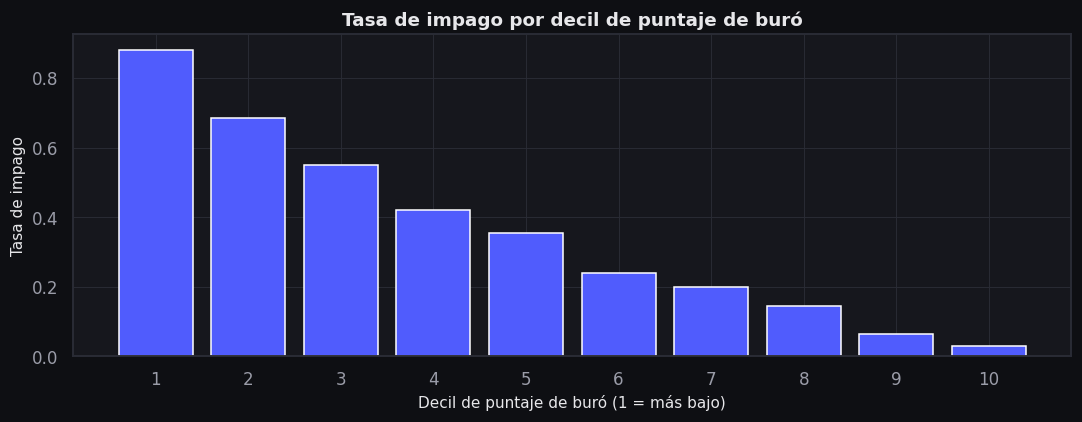

train: (9600, 27) · test: (2400, 27) · sin nulos en el modelo: True


In [6]:
riesgo_buro = duckdb.sql(f"""
    SELECT ntile(10) OVER (ORDER BY puntaje_buro) AS decil, puntaje_buro, "{config.TARGET}" AS y
    FROM crudo WHERE puntaje_buro BETWEEN 150 AND 950
""").df().groupby("decil").agg(desde=("puntaje_buro", "min"), hasta=("puntaje_buro", "max"), tasa_impago=("y", "mean"))
train, test = cargar_procesados()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(riesgo_buro.index.astype(str), riesgo_buro["tasa_impago"], color=PALETA["acento"])
ax.set(title="Tasa de impago por decil de puntaje de buró", xlabel="Decil de puntaje de buró (1 = más bajo)",
       ylabel="Tasa de impago")
plt.show()
figura_front("barras", "Tasa de impago por decil de puntaje de buró",
             {"categorias": [f"D{d}" for d in riesgo_buro.index], "series": [{"nombre": "Tasa de impago",
                                                                        "valores": riesgo_buro["tasa_impago"].round(4).tolist()}]},
             ejes={"x": "Decil de puntaje de buró (1 = más bajo)", "y": "Tasa de impago"}, clave="impago_por_decil_buro",
             opciones={"formato_y": "pct"})
print(f"train: {train.shape} · test: {test.shape} · sin nulos en el modelo: "
      f"{train[config.NUM_COLS_RAW + config.CAT_COLS].isna().sum().sum() == 0}")

**Interpretación.** La tasa de impago cae de forma monótona con el puntaje de buró: del 88,2 % en el decil más
bajo al 3,1 % en el más alto. Es la relación de negocio más fuerte del dataset y anticipa por qué el puntaje
domina las explicaciones del modelo.

## 3. F3 · Analizar y modelar: todos los modelos comparados

Clásicos (paso 5), redes neuronales en TensorFlow/Keras (paso 6), NLP con BERT y GPT-2 (paso 7) y Spark
MLlib (paso 9), todos evaluados en el mismo test con las mismas métricas.

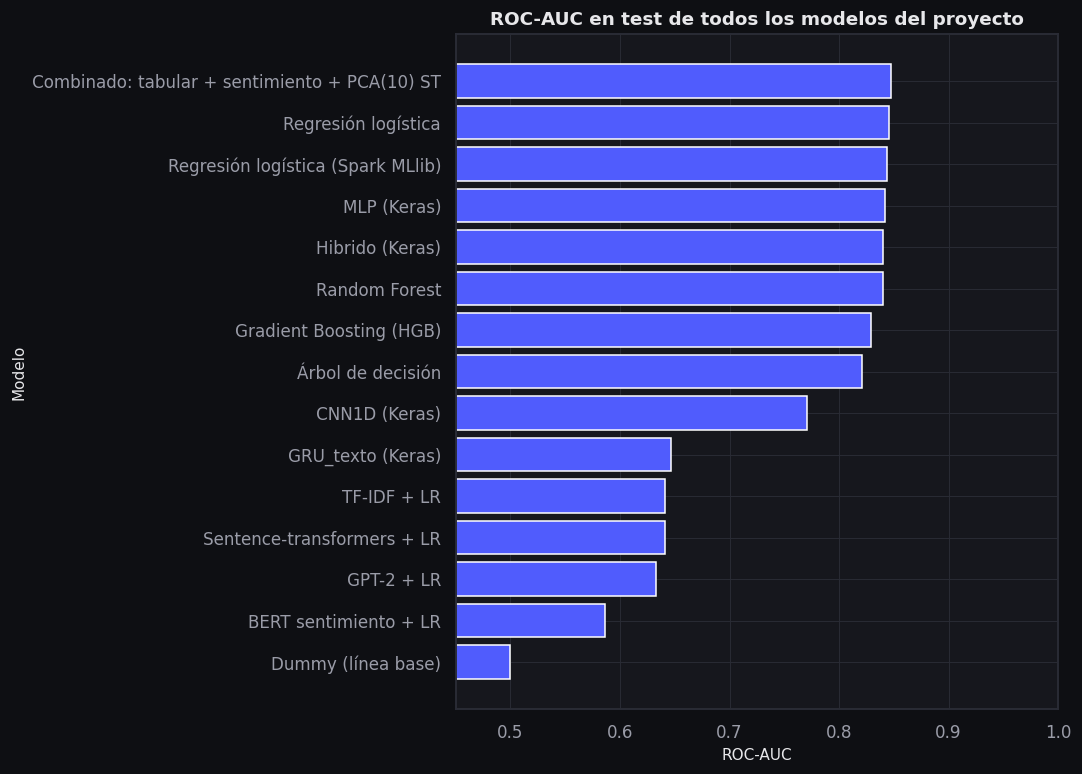

,modelo,familia,roc_auc,ks,brier,f1
0,Combinado: tabular + sentimiento + PCA(10) ST,nlp,0.8471,0.5550,0.1481,0.6934
1,Regresión logística,clásico,0.8459,0.5445,0.1488,0.6922
2,Regresión logística (Spark MLlib),big data,0.8441,0.5532,0.1493,0.6891
3,MLP (Keras),deep learning,0.8419,0.5353,0.1509,0.6778
4,Hibrido (Keras),deep learning,0.8399,0.5360,0.1531,0.6815
5,Random Forest,clásico,0.8397,0.5335,0.1526,0.6783
6,Gradient Boosting (HGB),clásico,0.8290,0.5069,0.1592,0.6764
7,Árbol de decisión,clásico,0.8207,0.4862,0.1613,0.6667
8,CNN1D (Keras),deep learning,0.7709,0.4144,0.1795,0.5947
9,GRU_texto (Keras),deep learning,0.6466,0.2722,0.2128,0.5313


In [7]:
filas = []
for nombre in ["resultados_clasicos", "resultados_dl", "resultados_nlp", "resultados_spark"]:
    ruta = config.MODEL_DIR / f"{nombre}.json"
    if ruta.exists():
        for f in leer_json(ruta)["modelos"]:
            filas.append({"modelo": f["modelo"], "familia": f["familia"], "roc_auc": f["test"]["roc_auc"],
                          "ks": f["test"]["ks"], "brier": f["test"]["brier"], "f1": f["test"]["f1"]})
comparacion = pd.DataFrame(filas).sort_values("roc_auc", ascending=False).reset_index(drop=True)
d = comparacion.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.4 * len(d) + 1.2))
ax.barh(d["modelo"], d["roc_auc"], color=PALETA["acento"])
ax.set(title="ROC-AUC en test de todos los modelos del proyecto", xlabel="ROC-AUC", ylabel="Modelo", xlim=(0.45, 1))
plt.show()
figura_front("barras_h", "ROC-AUC en test de todos los modelos del proyecto",
             {"categorias": d["modelo"].tolist(), "series": [{"nombre": "ROC-AUC", "valores": d["roc_auc"].tolist()}],
              "familias": d["familia"].tolist()},
             ejes={"x": "ROC-AUC", "y": "Modelo"}, clave="comparacion_global", opciones={"color_por": "familia", "min_x": 0.45})
comparacion

**Interpretación.** La tabla integra las cuatro familias de técnicas exigidas por el enunciado. El color
indica la familia; la elección del modelo servido (paso 8) no fue solo por AUC, sino por costo esperado,
equidad, calibración e interpretabilidad.

## 4. F4 · Evaluar y optimizar: el modelo servido

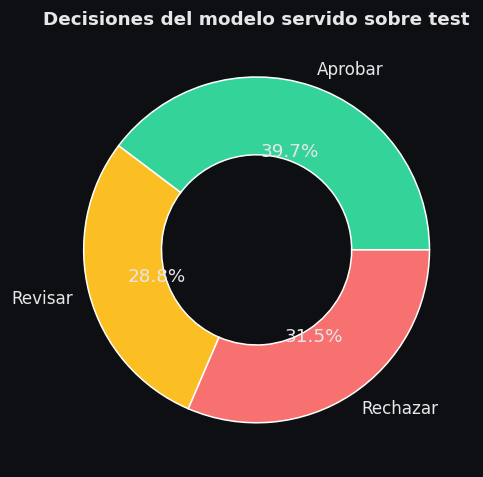

,métrica,test
0,roc_auc,0.8456
1,pr_auc,0.7675
2,ks,0.5384
3,brier,0.1491
4,accuracy,0.7829
5,precision,0.7205
6,recall,0.6370
7,f1,0.6762


In [8]:
dec = CARD["decision_test"]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.pie([dec["tasa_aprobacion"], dec["tasa_revision"], dec["tasa_rechazo"]], labels=["Aprobar", "Revisar", "Rechazar"],
       colors=[PALETA["bajo"], PALETA["medio"], PALETA["alto"]], autopct="%1.1f%%", wedgeprops={"width": 0.45})
ax.set(title="Decisiones del modelo servido sobre test")
plt.show()
figura_front("dona", "Decisiones del modelo servido sobre test",
             {"categorias": ["Aprobar", "Revisar", "Rechazar"],
              "valores": [dec["tasa_aprobacion"], dec["tasa_revision"], dec["tasa_rechazo"]]},
             clave="decisiones_test", opciones={"color_por": "banda", "formato": "pct"})
pd.DataFrame({"métrica": list(CARD["metricas_test"]), "test": list(CARD["metricas_test"].values())})

**Interpretación.** Cerca de cuatro de cada diez solicitudes se aprueban automáticamente, tres de cada diez
se rechazan y el resto va a revisión humana; la tasa de impago que queda entre los aprobados (en la card) es
la medida de negocio que la política controla.

In [9]:
eq = CARD["equidad_test"]
display(Markdown(f"**Equidad (test).** DI por sexo {eq['sexo']['disparate_impact']} (IC 95 % {eq['sexo']['di_ic95']}) · "
                 f"DI por edad {eq['edad']['disparate_impact']} (IC 95 % {eq['edad']['di_ic95']}) · "
                 f"variante elegida: `{CARD['variante_equidad']}`."))

**Equidad (test).** DI por sexo 0.9696 (IC 95 % [0.8682, 0.9974]) · DI por edad 0.8955 (IC 95 % [0.7803, 0.9771]) · variante elegida: `reweighing`.

## 5. F5 · Desplegar y comunicar: predicción de tres clientes

`predecir_cliente()` usa el mismo artefacto que la API. Después se llama a la API REST real en el mismo
proceso (`TestClient`); si la variable `API_URL` apunta a una API levantada (uvicorn o Docker), también se
consulta por HTTP.

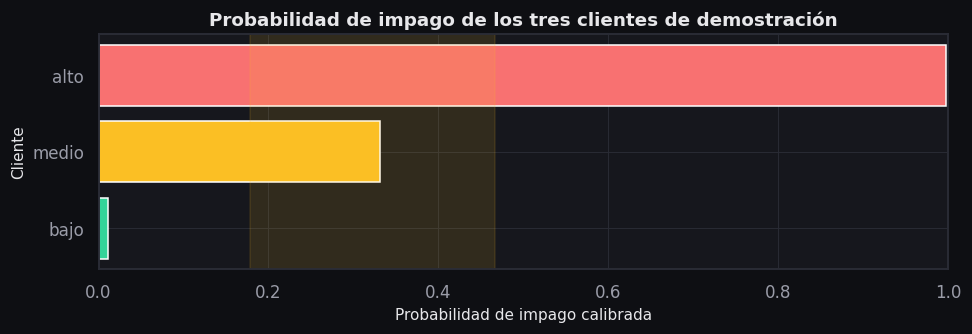

,cliente,probabilidad_impago,decision,banda,factor_principal
0,bajo,0.0106,aprobar,Bajo,puntaje_buro
1,medio,0.3315,revisar,Medio,puntaje_buro
2,alto,0.9969,rechazar,Alto,puntaje_buro


In [10]:
filas = []
for nombre, cliente in CLIENTES_DEMO.items():
    r = predecir_cliente(cliente, ARTEFACTOS)
    filas.append({"cliente": nombre, "probabilidad_impago": r["probabilidad_impago"], "decision": r["decision"],
                  "banda": r["banda_riesgo"], "factor_principal": r["factores_principales"][0]["variable"]})
demo = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(demo["cliente"], demo["probabilidad_impago"], color=[PALETA["bajo"], PALETA["medio"], PALETA["alto"]])
ax.axvspan(CARD["umbrales"]["aprobar"], CARD["umbrales"]["rechazar"], color=PALETA["medio"], alpha=0.12)
ax.set(title="Probabilidad de impago de los tres clientes de demostración", xlabel="Probabilidad de impago calibrada",
       ylabel="Cliente", xlim=(0, 1))
plt.show()
figura_front("barras_h", "Probabilidad de impago de los tres clientes de demostración",
             {"categorias": demo["cliente"].tolist(), "series": [{"nombre": "Probabilidad", "valores": demo["probabilidad_impago"].tolist()}],
              "referencias": [{"eje": "x", "valor": CARD["umbrales"]["aprobar"], "etiqueta": "aprobar <"},
                              {"eje": "x", "valor": CARD["umbrales"]["rechazar"], "etiqueta": "rechazar >"}]},
             ejes={"x": "Probabilidad de impago calibrada", "y": "Cliente"}, clave="clientes_demo",
             opciones={"formato_x": "pct", "color_por": "banda"})
demo

**Interpretación.** Cada cliente cae en una zona distinta de la política: el de bajo riesgo se aprueba, el
intermedio va a revisión y el de alto riesgo se rechaza. Las contribuciones exactas explican cada caso.

In [11]:
import logging
import sys

from fastapi.testclient import TestClient

for nombre in ("api", "api.service", "httpx"):  # registros de la API fuera de la salida del notebook
    logging.getLogger(nombre).setLevel(logging.WARNING)

sys.path.insert(0, str(config.BACK_DIR))  # el paquete `api` vive en Back/ (ruta derivada de config, no absoluta)
from api.main import app

with TestClient(app) as api:
    salud = api.get("/health").json()
    respuesta = api.post("/predict", json=CLIENTES_DEMO["medio"]).json()
print("GET /health →", salud)
print("POST /predict (cliente medio) →", {k: respuesta[k] for k in ["probabilidad_impago", "decision", "banda_riesgo"]})
if os.getenv("API_URL"):
    import requests

    print("HTTP real:", requests.post(f"{os.environ['API_URL']}/predict", json=CLIENTES_DEMO["medio"], timeout=10).json()["decision"])

GET /health → {'status': 'ok', 'modelo_version': '2.0.0', 'modelo_cargado': True, 'api_version': '2.0.0'}
POST /predict (cliente medio) → {'probabilidad_impago': 0.3315, 'decision': 'revisar', 'banda_riesgo': 'Medio'}


In [12]:
display(Markdown(
    f"**Resumen calculado.** Modelo v{CARD['version']} ({CARD['algoritmo']}). Test: AUC {CARD['metricas_test']['roc_auc']}, "
    f"KS {CARD['metricas_test']['ks']}, Brier {CARD['metricas_test']['brier']}. Decisiones: aprobar {dec['tasa_aprobacion']:.1%}, "
    f"revisar {dec['tasa_revision']:.1%}, rechazar {dec['tasa_rechazo']:.1%}; impago entre aprobados {dec['impago_en_aprobados']:.1%}. "
    f"{len(comparacion)} modelos comparados en total. La API real responde `{respuesta['decision']}` para el cliente intermedio."))

**Resumen calculado.** Modelo v2.0.0 (LogisticRegression calibrado (sigmoide, ensemble=False)). Test: AUC 0.8456, KS 0.5384, Brier 0.1491. Decisiones: aprobar 39.7%, revisar 28.8%, rechazar 31.5%; impago entre aprobados 9.8%. 15 modelos comparados en total. La API real responde `revisar` para el cliente intermedio.

## Hallazgos, ética, alcance y operación

**Hallazgos.** Cuatro variables financieras —puntaje de buró, deuda/ingreso, uso de cupo y moras— concentran
casi toda la capacidad predictiva. Ninguna técnica más compleja (redes, boosting, Spark, texto) supera de forma
demostrable a la regresión logística calibrada, que además es explicable con contribuciones exactas.

**Ética.** El sexo no entra al modelo. La disparidad por edad (DI 0,72 en la variante base) no desaparecía al
quitar la edad, porque viaja por variables legítimas; el *reweighing* la llevó a 0,90 en test con un costo del
0,6 %. La regla de 4/5 se usa como alerta, con IC, y se monitorea en producción (Ley 1581 de 2012).

**Alcance.** El dataset es sintético-realista, diseñado para el proyecto con las imperfecciones de una cartera
real (nulos, duplicados, edades imposibles, atípicos) y sin exponer datos personales. La metodología se replicó
además sobre German Credit (datos reales de UCI: AUC 0,786), donde la auditoría de equidad funciona igual. El
texto de la solicitud se evaluó con cuatro técnicas y la decisión usa el modelo tabular; los costos de la
política están documentados con su análisis de sensibilidad (ADR-002).

**Operación.** Monitoreo mensual de PSI, equidad por grupo y desempeño por cosecha, recalibración cuando el PSI
llega a 0,25 y champion–challenger para cada nueva versión (`docs/05_despliegue.md`).

## Conclusiones

1. **El producto final cumple PF1:** este notebook explora, prepara, modela, evalúa y predice la probabilidad de
   impago de un cliente con el mismo artefacto que sirve la API v2.0.0.
2. **Desempeño:** AUC 0,846 y KS 0,538 en test, muy por encima de la meta (0,70) y de la línea base (0,50).
3. **Decisión responsable:** aprobar 39,7 %, revisar 28,8 % y rechazar 31,5 %, con 9,8 % de impago entre los
   aprobados frente al 35,6 % de la cartera, y equidad por sexo (0,97) y edad (0,90) dentro de la regla de 4/5.
4. **Integración de los módulos:** programación (pasos 2–4), IA clásica, redes, NLP y Big Data (5–9), API y
   despliegue (10) y gestión ágil verificable (paso 0) convergen en una solución con potencial de implementación
   real (R4).